# CISS talk figures — simplified single plots for the slides

Nothing is re-implemented here: each section runs the relevant cells of a paper figure notebook (its parameters, data and `draw_*` functions, but not its previews or assembly) and then draws one panel per figure, with the details the talk doesn't need switched off or removed.

Plots are drawn in `paper` mode at paper size and saved as SVG + 600 dpi PNG in `ciss_figures/`. **Enlarge them on the slide as a whole** (text, lines and markers scale together, so they stay in proportion).

| file | source | change from the paper |
|---|---|---|
| `lda_accuracy` | `fig_lda` panel B | no syllable-space markers (`B_SYLLABLE_SPACE = False`) |
| `lda_accuracy_per_dim` | `fig_lda` panel D | no PCA or syllable lines |
| `design_matrix_1_trial` … `_8_lda`, `_legend` | `cartoon_design_matrix.py` (new, mock data) | replaces `fig_lda` panel A + `cartoon_time_warping` for the talk: one visual language from trial to design matrix |
| `time_horizon_session_measures` | `fig_time_horizon` panel g | no shaded recording-rig band (nor its 'rec. rig' label), darker dotted line, + wheel speed |
| `time_horizon_by_epoch`, `time_horizon_epoch_mean` | `learning_individuality/epoch_session_measures.py` (new) on `syllable_correlations`' profiles | the same test per trial epoch, and the epoch average |
| `ld1_ld2_mice_spokes` | `fig_ld1` panel A | each session joined to its mouse mean by a thin line |
| `ld1_syllable_corr_paw0`, `ld1_syllable_corr_full` | `fig_ld1` panel B | build-up: both frames with only the Paw 0 trace (its own null band), then the full panel at the same size and y-range |

In [1]:
import sys, pathlib, json, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
if str(PI) not in sys.path:
    sys.path.insert(0, str(PI))
import paper_style as ps

OUT = FIGDIR / 'ciss_figures'
OUT.mkdir(exist_ok=True)

def save(fig, name):
    for ext, kw in [('svg', {}), ('png', {'dpi': 600})]:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight', transparent=True, **kw)
    print('saved', OUT / name)

## Running cells of a source notebook

`run_cells` executes the code cells of a figure notebook whose source contains any of `markers`, in order, into one namespace (`overrides` are applied right after the parameters cell, so they win over the notebook's defaults). `plt.show` is a no-op meanwhile, so the notebooks' own single-panel previews are not drawn.

In [2]:
def run_cells(name, markers, overrides=None, cwd=FIGDIR):
    nb = json.loads((FIGDIR / f'{name}.ipynb').read_text())
    ns = {'__name__': '__main__'}
    show, plt.show = plt.show, (lambda *a, **k: plt.close('all'))
    old = pathlib.Path.cwd()
    import os; os.chdir(cwd)
    try:
        for c in nb['cells']:
            src = ''.join(c['source'])
            if c['cell_type'] != 'code' or not any(m in src for m in markers):
                continue
            exec(compile(src, f'{name}', 'exec'), ns)
            if overrides and 'FIG = ' in src:          # the parameters cell
                ns.update(overrides)
    finally:
        plt.show = show; os.chdir(old); plt.close('all')
    return ns

## LDA — mouse identification accuracy (`fig_lda` B and D)

Setup, parameters, data and the panel B / D cells of `fig_lda`.

In [3]:
LDA = run_cells('fig_lda', ['import paper_style as ps', "FIG = 'fig_lda'", 'RES = pickle.load',
                            'def draw_B', 'def draw_D'],
                overrides={'B_SYLLABLE_SPACE': False})

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
syllable_file 8_k_10_bin_syllables_02-10-2026, written 02-11-2026 11:27, n_sessions 260, n_mice 56, n_labs 10, n_repeats 20, n_repeats_one_out 3, n_splits 50, n_stability 100
Session out        LDA 0.859  syllable space 0.696  chance 0.018  (n = 20)
½ mice out         LDA 0.810  syllable space 0.747  chance 0.036  (n = 50)
½ labs out         LDA 0.786  syllable space 0.730  chance 0.036  (n = 50)
Session out       LD1 alone 0.08, 5 dims 0.51, 10 dims 0.72, 90% of max at k = 13
Half of mice out  LD1 alone 0.13, 5 dims 0.51, 10 dims 0.69, 90% of max at k = 13
Half of labs out  LD1 alone 0.12, 5 dims 0.46, 10 dims 0.65, 90% of max at k = 14
Syllable space    5 dims 0.21, 10 dims 0.34, 45 dims 0.59, all 360: 0.69
PCA               5 dims 0.41, 10 dims 0.59, max 0.70


### Accuracy across held-out sessions, mice and labs — LDA space only

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/lda_accuracy


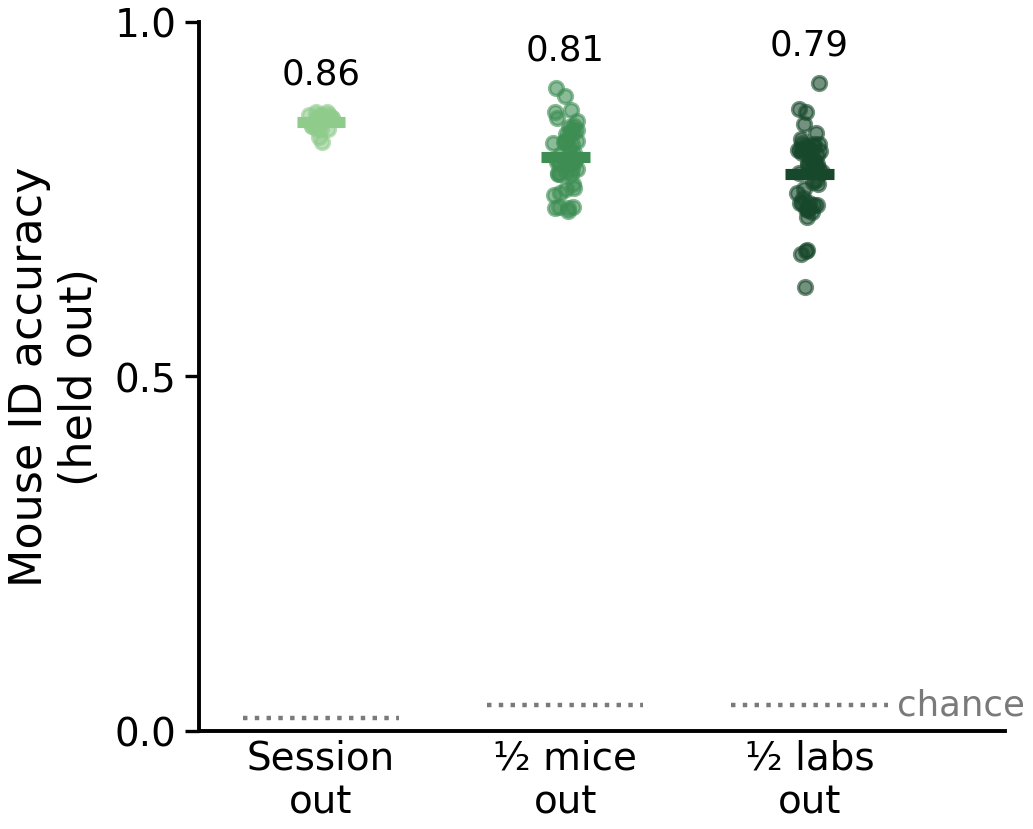

In [4]:
fig = plt.figure(figsize=(2.6, 2.3))
LDA['draw_B'](fig, fig.add_gridspec(1, 1)[0])
save(fig, 'lda_accuracy'); plt.show()

### Accuracy in the first k dimensions — LDA only (no PCA or syllable lines)

`draw_D` is the paper's; the PCA and syllable lines are removed from the axes afterwards (and the legend redrawn), so the paper function stays untouched.

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/lda_accuracy_per_dim


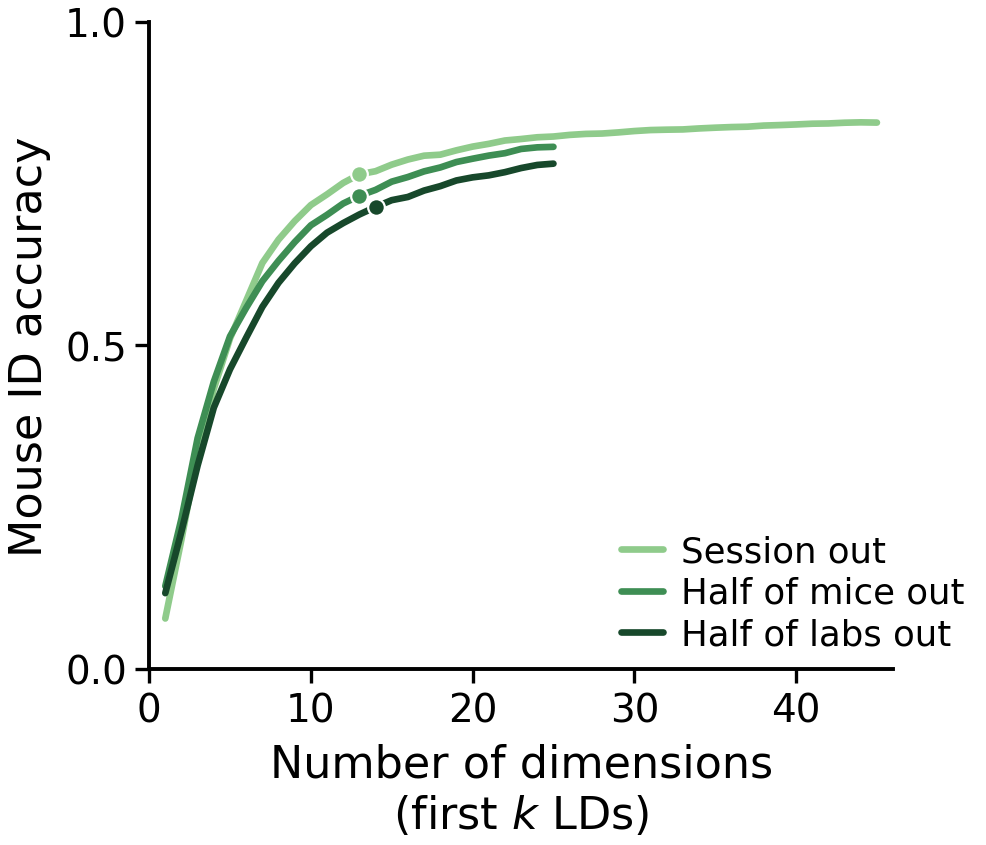

In [5]:
fig = plt.figure(figsize=(2.4, 2.1))
ax, = LDA['draw_D'](fig, fig.add_gridspec(1, 1)[0])
for ln in [l for l in ax.lines if l.get_label().startswith(('PCA', 'Syllables'))]:
    ln.remove()
ax.set_xlabel('Number of dimensions\n(first $k$ LDs)')
ax.legend(frameon=False, fontsize=LDA['fs_small'], loc='lower right', bbox_to_anchor=(1.12, 0), handlelength=1.2,
          labelspacing=0.2, borderaxespad=0.1)
save(fig, 'lda_accuracy_per_dim'); plt.show()

## From trials to the LDA design matrix (real data)

One visual language throughout (`cartoon_design_matrix.py`): a syllable is always a cell in its own colour, and a probability is always a bar **height** on one scale. That makes each step a rearrangement of the same coloured bars:

1. one trial in real time (60 Hz frames: paw strip, whisking, licking)
2. time-warped to 40 bins (10 per epoch, mode syllable)
3. many trials, each a 40-bin strip
4. per bin, how often each syllable occurs → stacked histogram = the session
5. the stack pulled apart, one row per syllable (same bars, same heights) = the session image
6. flattened bin by bin → session vector
7. sessions stacked → design matrix, labelled by mouse
8. shrinkage LDA → each mouse a cluster

All steps use REAL data (`cd.Real`): the paper's syllable file and states files, with the paper's paw states (`ps.use_paw_states('uniform')`: the files' paw codes are relabelled at load with `ps.paw_codes`, as in `fig_segmentation`). The session is the Proficient session whose 40-bin profile is closest to the mean of all sessions (a typical one); the example trial is the one whose epoch durations are closest to that session's medians. Steps 1–2 show its frames from the states file, and its 40 bins are the syllable file's own `binned_sequence`; trial 1 in step 3 is that trial; steps 4–6 show the mean profile over ALL sessions (each session weighted once; `profile='session'` would show the typical session alone). Step 7 uses real sessions of four real mice (the session's mouse first). Only step 8 (LDA space) is still a cartoon. `cd.Mock` is kept for the simulated version. The paper's dropped reference paw state is not shown (10 rows, not 9).

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


session d16a9a8d-5f42-4b49-ba58-1746f807fcc1 (CSHL059), 444 complete trials; example trial 134 (epochs [0.97 0.55 0.3  1.58] s); histogram = mean of all 332 sessions; design-matrix mice ['CSHL059', np.str_('CSHL049'), np.str_('ZFM-01935'), np.str_('ZFM-01592')] ([5, 4, 4, 3] sessions)
saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_1_trial


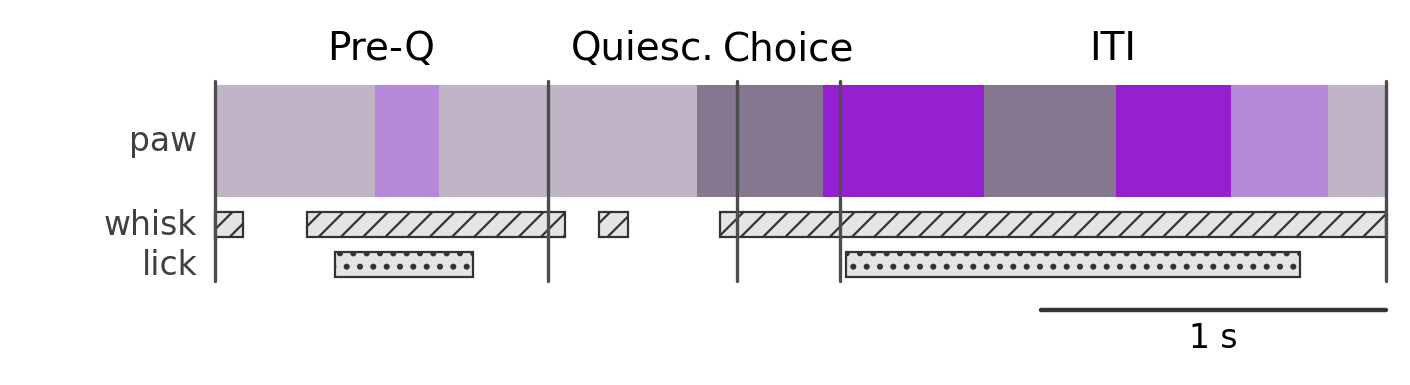

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_2_warp


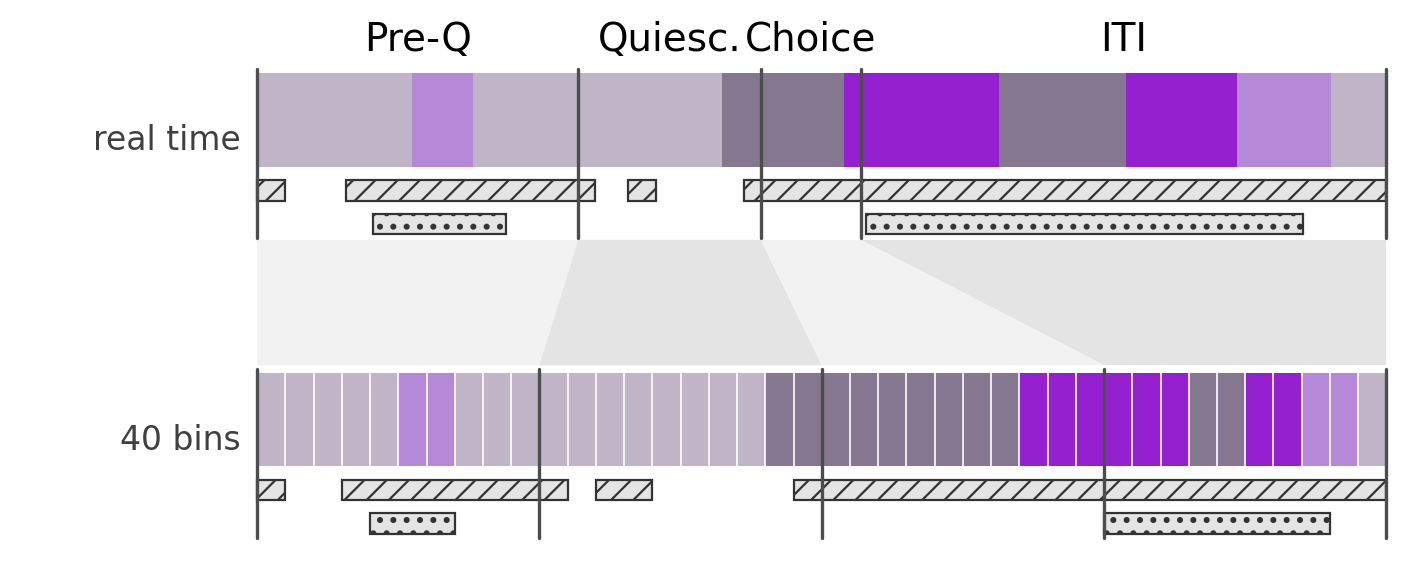

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_3_trials


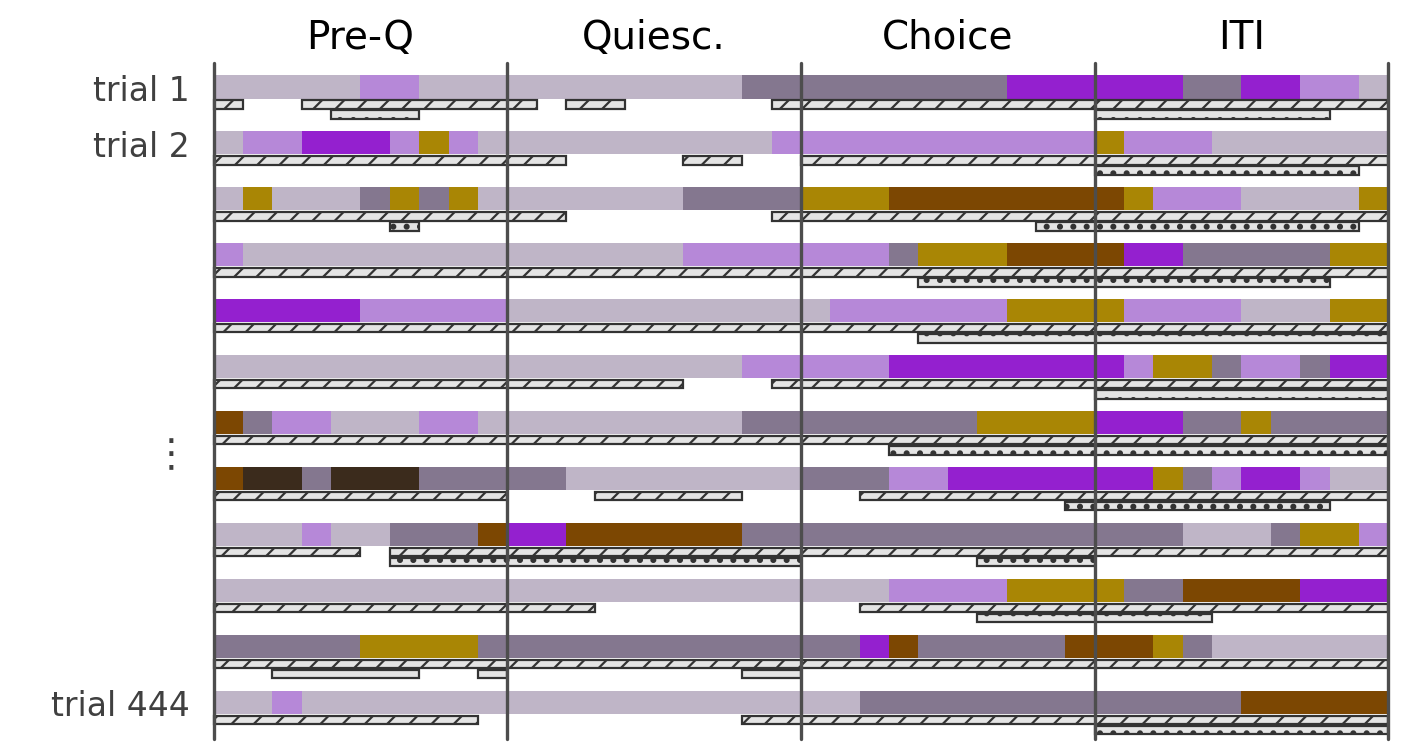

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_4_histogram


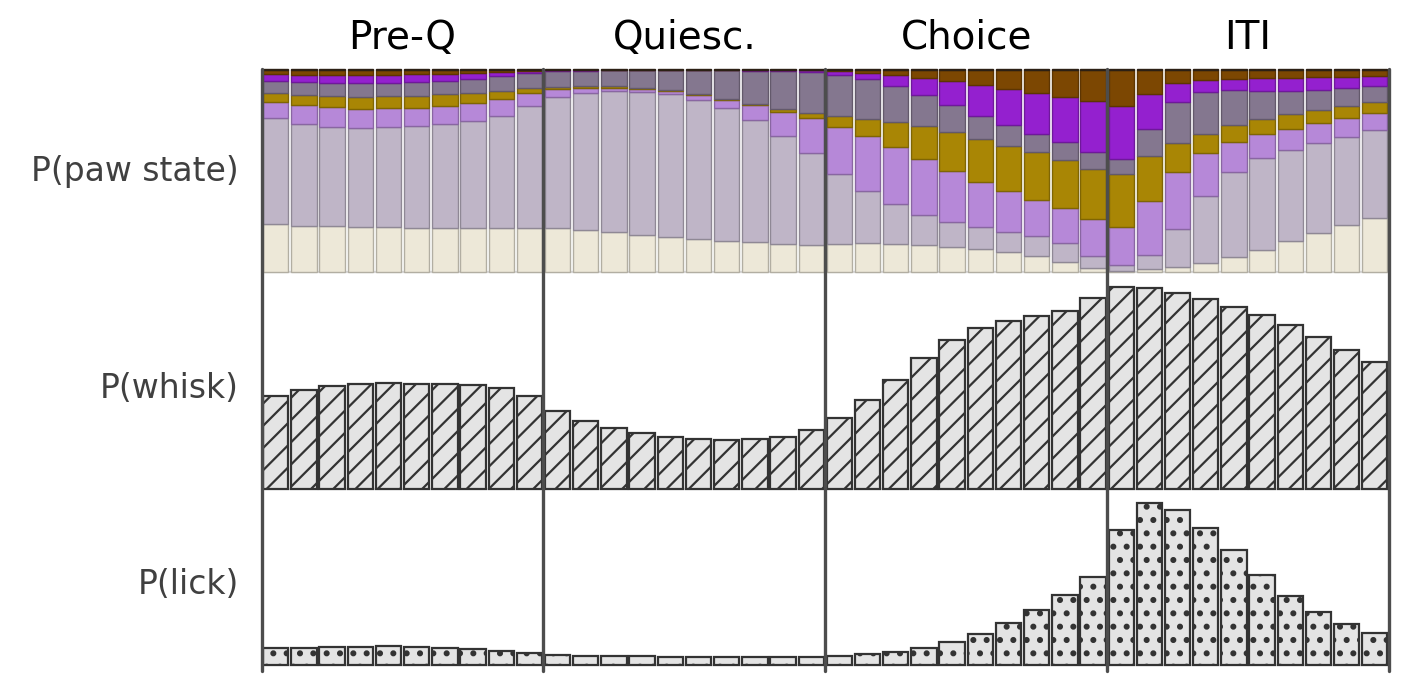

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_5_unstack


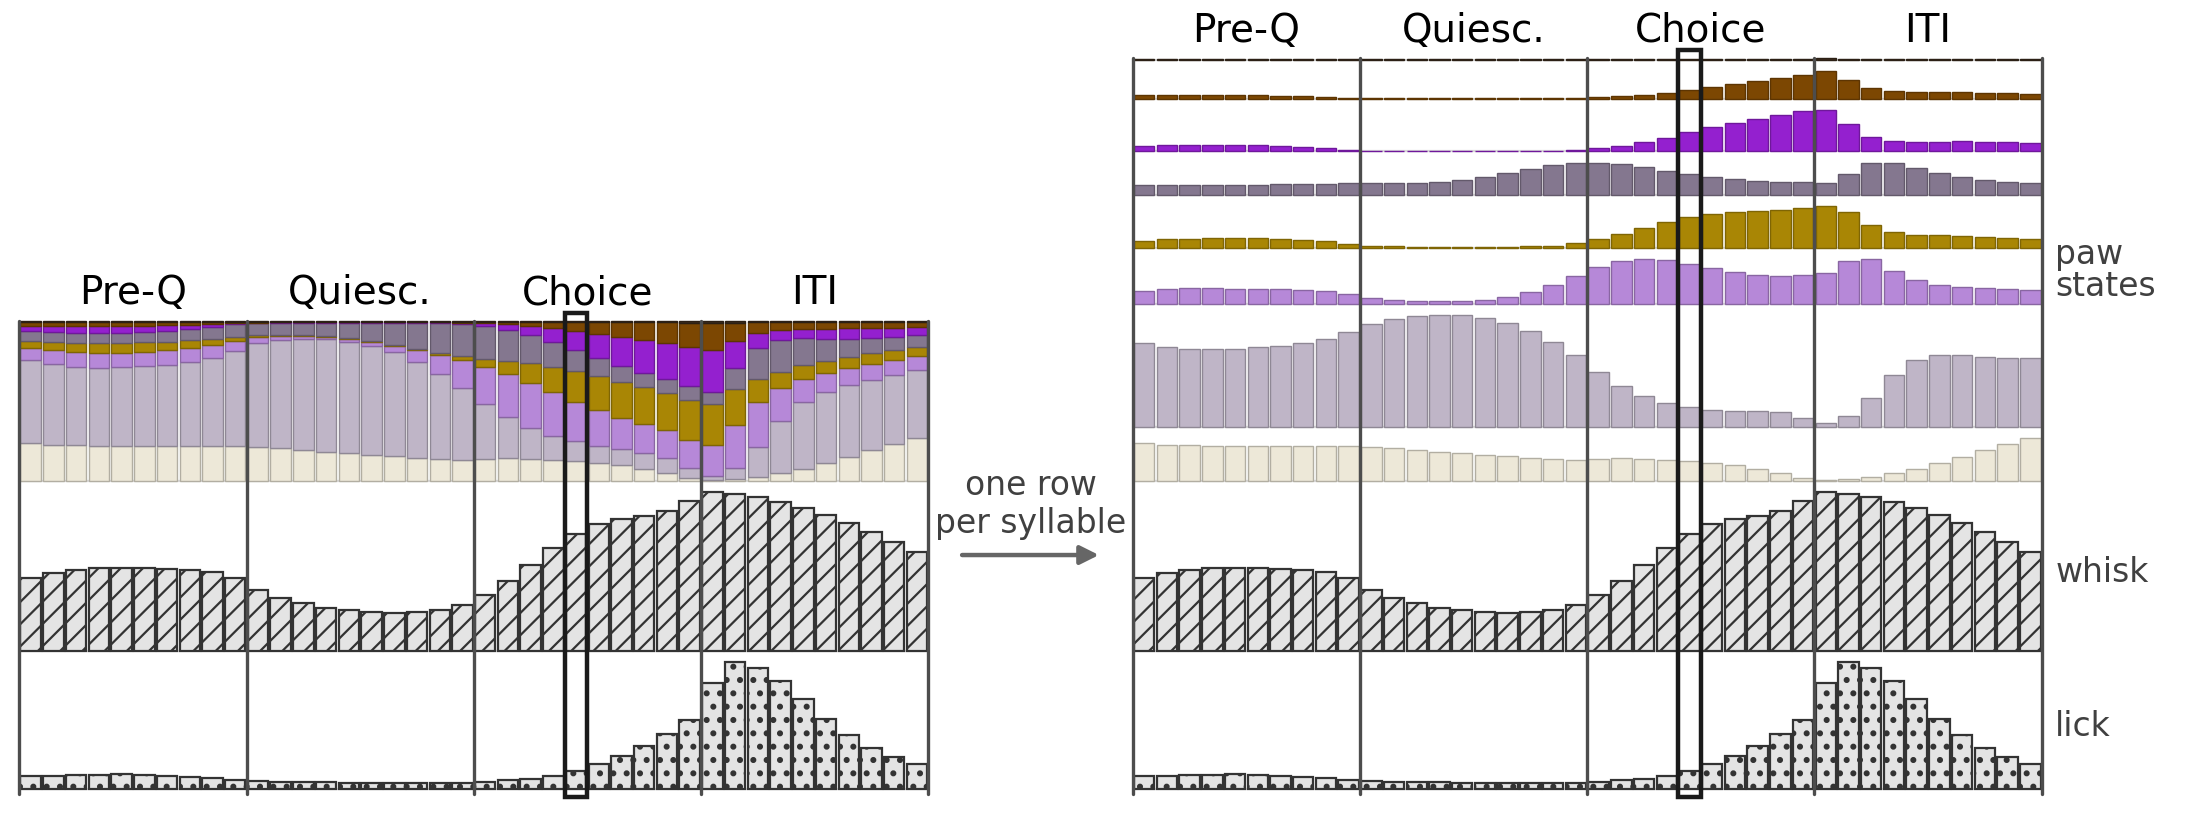

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_6_flatten


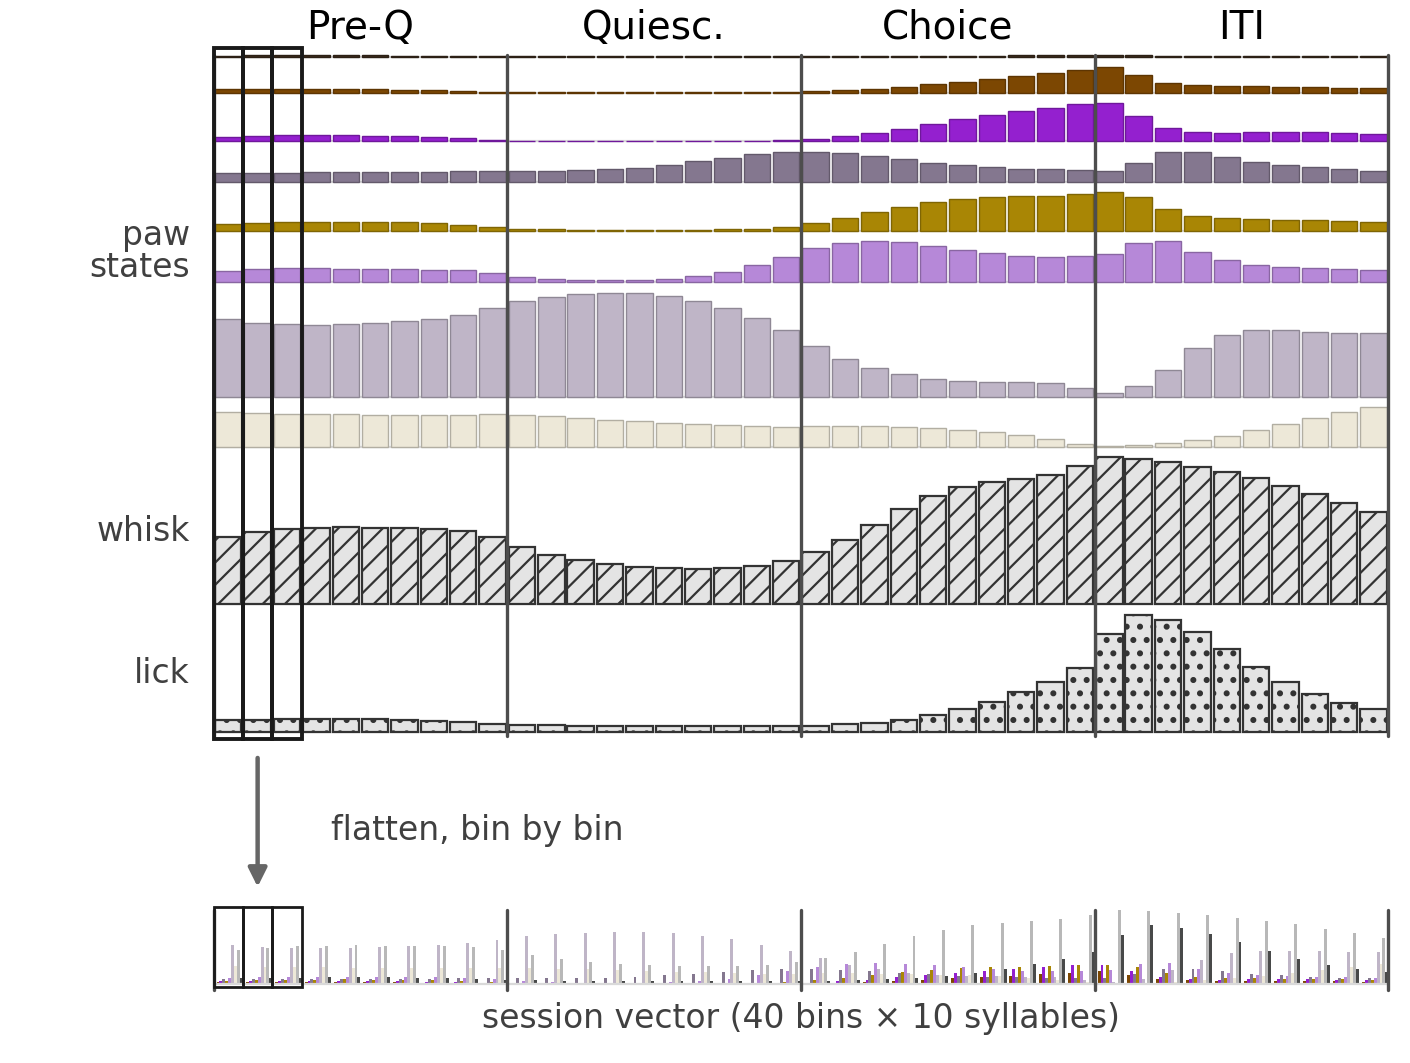

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_7_design_matrix


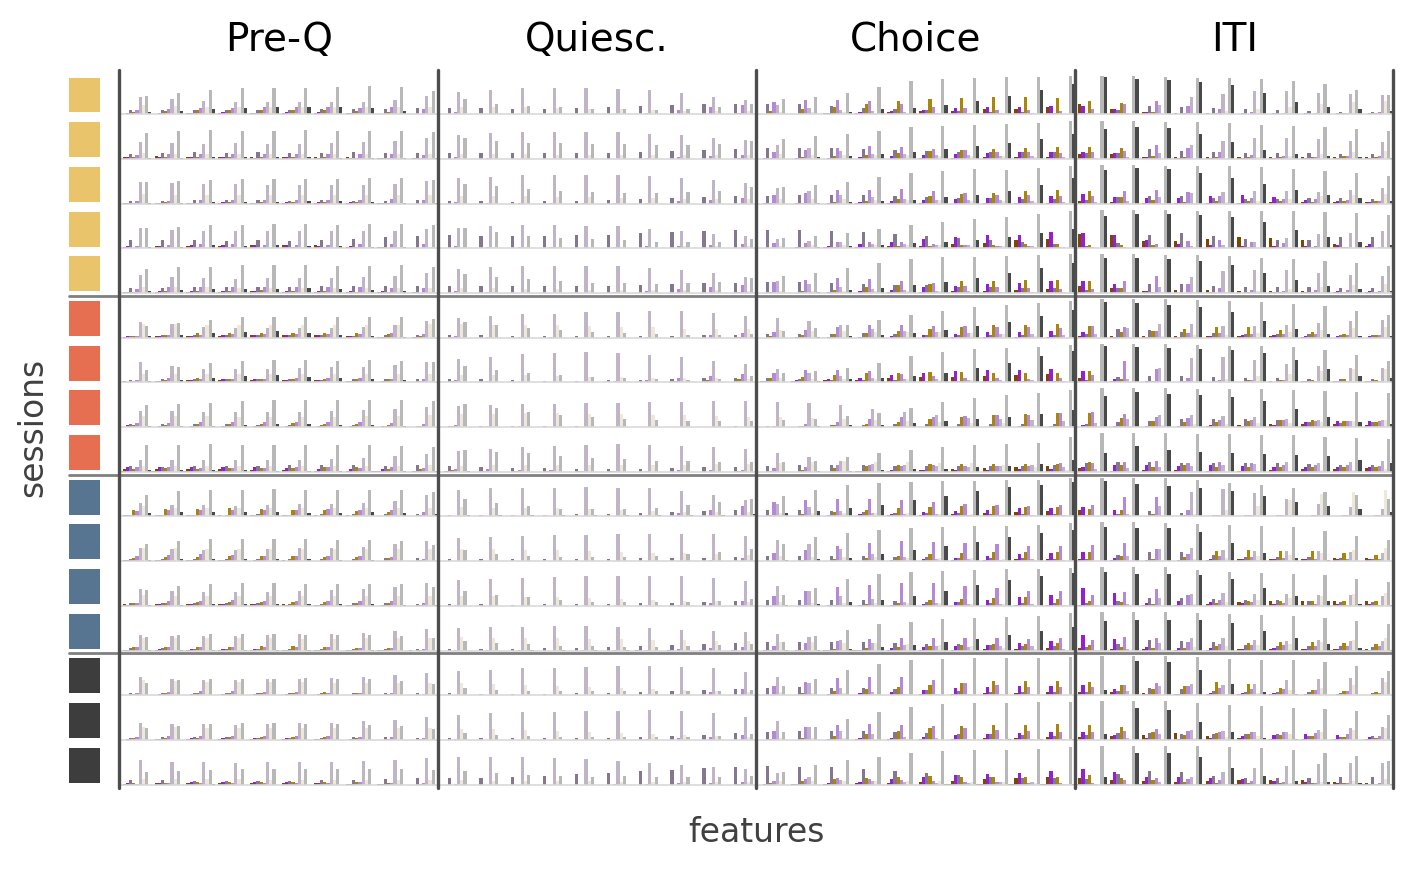

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_8_lda


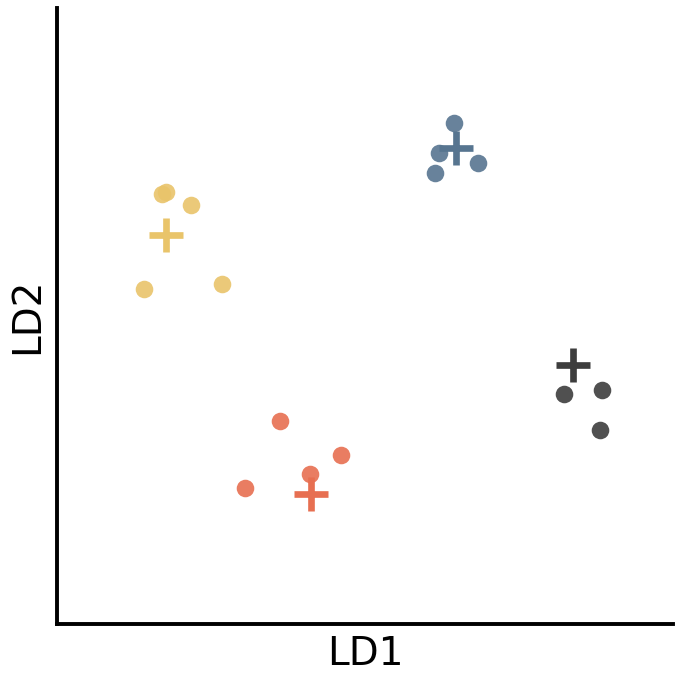

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/design_matrix_legend


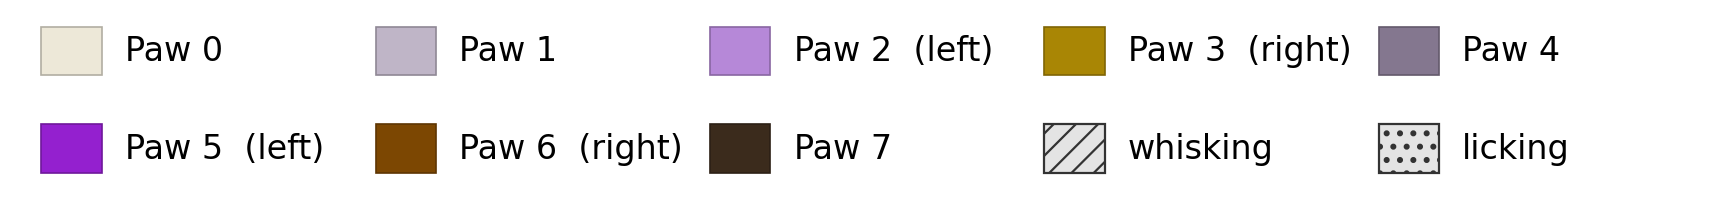

{'colors': ['#EDE8D8',
  '#BFB5C7',
  '#857691',
  '#A96BD3',
  '#B79C50',
  '#7B09AE',
  '#985800',
  '#462600'],
 'vigor_order': [0, 1, 4, 3, 2, 6, 5, 7],
 'lateral': {'left': [3, 5], 'right': [4, 6], 'symmetric': [0, 1, 2, 7]},
 'states_dir': 'data/states_files (identifiable_states // 100)',
 'profiles': 'vigor/paw_bias/state_profiles_19Ago2026.csv',
 'syllable_paw_map': [0, 1, 2, 3, 4, 5, 6, 7]}

In [6]:
import importlib
import cartoon_design_matrix as cd
importlib.reload(cd)
ps.use('paper')
ps.use_paw_states('uniform')        # the paper's paw states: the files' codes are relabelled at load (ps.paw_codes)
# REAL data: the paper's syllables -- a typical Proficient session, one of its trials
DM = cd.Real(PI / 'data' / '8_k_10_bin_syllables_02-10-2026', PI / 'data' / 'states_files', profile='all')
print(f'session {DM.eid} ({DM.mouse_name}), {DM.n_trials} complete trials; example trial {DM.trial:.0f} '
      f'(epochs {np.round(DM.dur, 2)} s); histogram = mean of all {DM.n_sessions} sessions; design-matrix mice {DM.mice} ({DM.n_mice} sessions)')

DM_STEPS = [('1_trial', cd.draw_trial, (4.5, 1.2)),
            ('2_warp', cd.draw_warp, (4.5, 1.8)),
            ('3_trials', cd.draw_raster, (4.5, 2.4)),
            ('4_histogram', cd.draw_hist, (4.5, 2.2)),
            ('5_unstack', cd.draw_unstack, (7.0, 2.6)),
            ('6_flatten', cd.draw_flatten, (4.5, 3.4)),
            ('7_design_matrix', cd.draw_design, (4.5, 2.8)),
            ('8_lda', cd.draw_lda, (2.0, 2.0))]
for name, fn, size in DM_STEPS:
    fig, ax = plt.subplots(figsize=size)
    fn(ax, DM)
    save(fig, f'design_matrix_{name}'); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 0.6))
cd.legend(ax)
save(fig, 'design_matrix_legend'); plt.show()
ps.use_paw_states('production')     # back to paper_style's default for the cells below

## Time horizon — session-wide measures against Proficient (`fig_time_horizon` g), plus the wheel

**How it is computed (all whole-session, no trial alignment):**
- per session, one number per measure over the whole video:
  - whisking / licking: fraction of time in the active HMM state (`habituation/3_hmm_state_measures.py`);
  - left-paw vigor: each frame scored by its left paw + wheel state's left-paw wavelet power (`state_palette.csv`), averaged over the session. The wavelets are session-z-scored, so this is how much of the session sits in high- vs low-power states, not raw speed;
  - **wheel speed (added here):** mean |wheel velocity| over the session, from the design matrices' `avg_wheel_vel` (rad/s). This is raw speed from the rotary encoder, so unlike the camera measures it doesn't depend on the rig;
- per mouse, the mean over its sessions at each timepoint;
- Spearman across mice between each earlier timepoint and the same mouse's Proficient mean (every mouse with both, so n differs per point);
- Prof. = each mouse's Proficient sessions split by date into odd and even, the two halves correlated (the reliability ceiling);
- filled = BH FDR q < 0.05, over all the tests drawn. Adding the wheel enlarges that family, so the q values of the other three measures differ slightly from the paper's.

Drawn with the paper's `draw_g`. Afterwards the grey recording-rig band and its 'rec. rig' label are removed, the dotted line before Prof. is darkened, every point is connected (Pre-rec to Prof. too), and left-paw vigor is drawn in a bright violet (the paper's left-paw hue).

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
   feature         tp    rho      p  n      q
whisk_frac      Early 0.3869 0.0060 49 0.0120
whisk_frac       Late 0.3170 0.0184 55 0.0276
whisk_frac    Pre-rec 0.3748 0.0133 43 0.0228
whisk_frac Proficient 0.7052 0.0000 80 0.0000
 lick_frac      Early 0.3030 0.0385 47 0.0513
 lick_frac       Late 0.1507 0.2720 55 0.3264
 lick_frac    Pre-rec 0.4376 0.0033 43 0.0080
 lick_frac Proficient 0.6729 0.0000 81 0.0000
 paw_vigor      Early 0.1200 0.4115 49 0.4489
 paw_vigor       Late 0.0628 0.6489 55 0.6489
 paw_vigor    Pre-rec 0.5954 0.0000 43 0.0001
 paw_vigor Proficient 0.6402 0.0000 76 0.0000
            sessions  mice  median_speed
timepoint                               
Early             49    49         0.249
Late              55    55         0.423
Pre-rec          117    44         0.362
Proficient       342   103         0.335
    feature         tp    rho      p  n      q
 whisk_frac      Early 0.3869 

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/time_horizon_session_measures


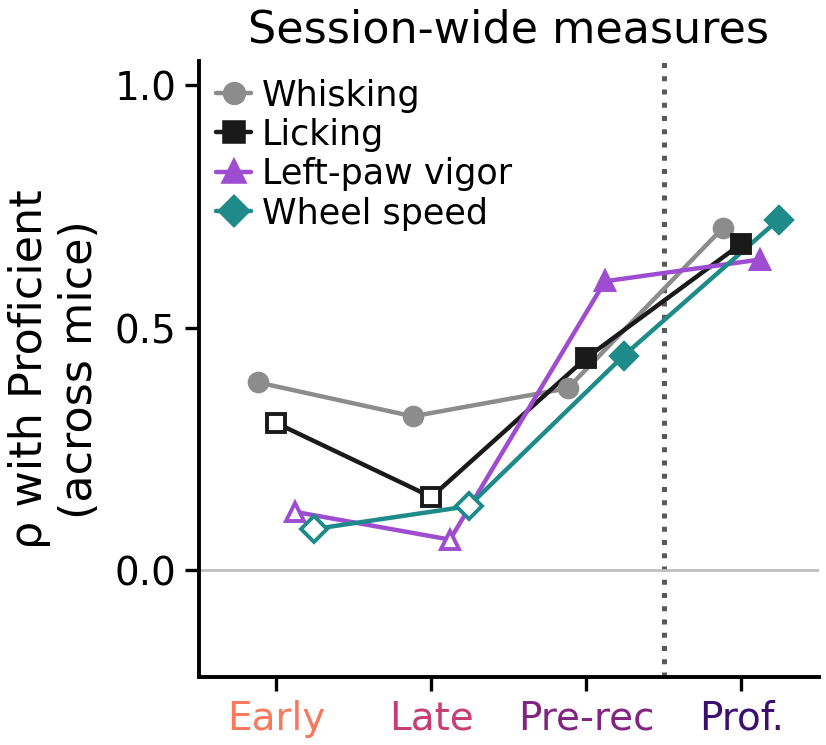

In [7]:
TH = run_cells('fig_time_horizon', ["FIG = 'fig_time_horizon'", 'def draw_g'])
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

WHEEL_CACHE = FIGDIR / 'cache' / 'ciss_wheel_speed_sessions.csv'
WHEEL_COLOR = '#1F8A8A'          # teal: paper_style's wheel hue (WHEEL_HUE = 180)

def wheel_sessions():
    # per session: mean |wheel velocity| over the whole design matrix (every frame bin of the video)
    if WHEEL_CACHE.exists():
        return pd.read_csv(WHEEL_CACHE)
    rows = []
    for tp, d in TH['STAGE_DIRS'].items():
        for f in sorted(d.glob('design_matrix_*')):
            v = pd.read_parquet(f, columns=['avg_wheel_vel'])['avg_wheel_vel'].to_numpy()
            rows.append(dict(timepoint=tp, eid=f.name[14:50], mouse_name=f.name[51:],
                             wheel_speed=np.nanmean(np.abs(v)), n_bins=np.isfinite(v).sum()))
    out = pd.DataFrame(rows)
    out.to_csv(WHEEL_CACHE, index=False)
    return out

def wheel_corr(ws):
    # the same tests as fig_time_horizon's prof_corr_table, for the wheel
    m = ws.groupby(['timepoint', 'mouse_name'])['wheel_speed'].mean().unstack(0)
    prof = ws[ws['timepoint'] == 'Proficient'].assign(date=lambda x: x['eid'].map(TH['SESSION_DATE']))
    prof = prof.dropna(subset=['date']).sort_values(['mouse_name', 'date'])
    prof['half'] = prof.groupby('mouse_name').cumcount() % 2
    halves = prof.groupby(['mouse_name', 'half'])['wheel_speed'].mean().unstack('half').dropna()
    rows = []
    for tp in TH['PC_TPS']:
        d = halves.set_axis([tp, 'Proficient'], axis=1) if tp == 'Proficient' else m[[tp, 'Proficient']].dropna()
        r = spearmanr(d.iloc[:, 0], d.iloc[:, 1])
        rows.append(dict(feature='wheel_speed', tp=tp, rho=r.statistic, p=r.pvalue, n=len(d)))
    return pd.DataFrame(rows)

WS = wheel_sessions()
print(WS.groupby('timepoint').agg(sessions=('eid', 'size'), mice=('mouse_name', 'nunique'),
                                  median_speed=('wheel_speed', 'median')).round(3))
corr = pd.concat([TH['PROF_CORR'].drop(columns='q'), wheel_corr(WS)], ignore_index=True)
corr['q'] = multipletests(corr['p'], method='fdr_bh')[1]       # one FDR family over everything drawn
print(corr.round(4).to_string(index=False))
TH['PROF_CORR'] = corr
PAW_COLOR = ps.oklch_to_hex(0.58, 0.20, 310)   # bright violet: the paper's left-paw hue (310), at the wheel teal's lightness
TH['PC_FEATS'] = [(f, l, PAW_COLOR if f == 'paw_vigor' else c, m) for f, l, c, m in TH['PC_FEATS']] + \
                 [('wheel_speed', 'Wheel speed', WHEEL_COLOR, 'D')]

def finish_g(ax, table, feats):
    # talk version of draw_g: no recording-rig band / label, darker dotted line, Pre-rec joined to Prof.
    for patch in list(ax.patches):                   # the axvspan: the only patch on these axes
        patch.remove()
    for t in [t for t in ax.texts if t.get_text() == 'rec. rig']:
        t.remove()
    for ln in ax.lines:
        if ln.get_linestyle() == ':':
            ln.set_color('0.35'); ln.set_linewidth(0.9)
    tps = TH['PC_TPS']
    for k, (f, _, col, _) in enumerate(feats):       # same x offsets as draw_g
        d = table[table['feature'] == f].set_index('tp').reindex(tps)['rho'].to_numpy()
        xs = np.arange(len(tps)) + (k - 1) * 0.12
        ax.plot(xs[-2:], d[-2:], '-', color=col, lw=0.8, zorder=2)

fig = plt.figure(figsize=(2.0, 2.0))
ax, = TH['draw_g'](fig, fig.add_gridspec(1, 1)[0])
finish_g(ax, TH['PROF_CORR'], TH['PC_FEATS'])
save(fig, 'time_horizon_session_measures'); plt.show()

## Time horizon per trial epoch, and the epoch average

The same test as above, but one number per session **and trial epoch** instead of per whole session (`learning_individuality/epoch_session_measures.py`). The input is the time-warped syllable profiles of `syllable_correlations.ipynb` (left paw + wheel syllables, its QC exclusions; per bin, the fraction of the session's trials in each syllable):

- whisking / licking: mean P(whisk) / P(lick) over the epoch's 10 bins;
- left-paw vigor / **wheel power**: Σ P(state) × that left paw + wheel state's left-paw / wheel power (`state_palette.csv`). These are session-z-scored state powers, so here the wheel is a *power* (time in high- vs low-wheel states), not the raw encoder speed used in the whole-session panel above.

Per mouse mean → Spearman across mice vs Proficient (Prof. = odd vs even sessions), exactly as panel g. Filled = BH FDR q < 0.05: one family over all per-epoch tests, a separate one over the epoch-mean tests.

**Epoch mean**: the mean of the four epochs' ρ (Fisher z), so each epoch counts once. Its p is a permutation that respects the trial structure: per permutation the mice of the earlier timepoint are shuffled once and that same shuffle is applied to all four epochs, so the dependence between epochs (same mice) is in the null.

The mice are those of `syllable_correlations` (n differs from the whole-session panel, which uses every session with HMM fits).

In [8]:
import sys
sys.path.insert(0, str(PI / 'learning_individuality'))
import epoch_session_measures as esm
importlib.reload(esm)

TH_SC = run_cells('fig_time_horizon', ["FIG = 'fig_time_horizon'", 'def load_panels', 'SC = load_panels'])
SC = TH_SC['SC']
PAL = pd.read_csv(PI / 'data' / TH['PAW_STATES'] / 'state_palette.csv').set_index('state').sort_index()
assert list(SC['FEATURE_NAMES'][:8]) == [f'Paw {i}' for i in range(8)]       # the joint states, palette numbering
V = esm.session_epoch_measures(SC['recon'], PAL['left_paw power'].to_numpy(), PAL['wheel power'].to_numpy())

EP_CACHE = FIGDIR / 'cache' / 'ciss_epoch_correlations.csv'
if EP_CACHE.exists():
    EPC = pd.read_csv(EP_CACHE)
else:
    EPC = esm.epoch_correlations(V, np.asarray(SC['mice']), np.asarray(SC['timepoint']), np.asarray(SC['sessions']),
                                 TH['SESSION_DATE'], TH['PC_TPS'], n_perm=10000)
    EPC.to_csv(EP_CACHE, index=False)
mean_rows = EPC['epoch'] == 'Epoch mean'
EPC['q'] = np.nan
EPC.loc[~mean_rows, 'q'] = multipletests(EPC.loc[~mean_rows, 'p'], method='fdr_bh')[1]
EPC.loc[mean_rows, 'q'] = multipletests(EPC.loc[mean_rows, 'p'], method='fdr_bh')[1]
print(EPC.pivot_table(index=['feature', 'tp'], columns='epoch', values='rho', sort=False)
      [esm.EPOCHS + ['Epoch mean']].round(2).to_string())
print('\nn mice per comparison:', EPC.groupby('tp')['n'].first().to_dict())

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
paper_style: poster mode, spines=lb, font 16 pt, panels 7.0x5.0 in, save 300 dpi
base_path: /home/ines/repositories/representation_learning_variability/paper-individuality/data/


syllables: left_paw_wheel k=8, state space 'stages', lick HMM 'auto', 10 bins/phase
exclusions from the sheet (filtered_out): Early 15, Late 9, Pre-rec 76, Proficient 12, Habituation 0
  OK   Early left_paw_wheel_k8_stages_lick-100ms_session_1_8_k_10_bin_syllables_06-10-2026
  OK   Late left_paw_wheel_k8_stages_lick-100ms_last_training_8_k_10_bin_syllables_06-10-2026
  OK   Pre-rec left_paw_wheel_k8_stages_lick-100ms_biased_8_k_10_bin_syllables_06-10-2026
  OK   Proficient left_paw_wheel_k8_stages_lick-standard_proficient_8_k_10_bin_syllables_06-10-2026
  Early         47 sessions ->   47 after prob_sessions/min_sessions ->   37 after the Early exclusion list (0 + 10 dropped)
  Late          55 sessions ->   55 after prob_sessions/min_sessions ->   49 after the Late exclusion list (0 + 6 dropped)


  Pre-rec      116 sessions ->  116 after prob_sessions/min_sessions ->   96 after the Pre-rec exclusion list (0 + 20 dropped)


  Proficient   332 sessions ->  330 after prob_sessions/min_sessions ->  330 after the Proficient exclusion list (2 + 0 dropped)


OK 512 sessions, 360 features, 101 mice
            sessions  mice
timepoint                 
Early             37    37
Late              49    49
Pre-rec           96    37
Proficient       330   101
state colours: state_palette.csv of left_paw_wheel / stages
reconstructed: 512 sessions x 40 trial bins x 10 features (reference states restored)
  Early        37 mice
  Late         49 mice
  Pre-rec      37 mice
  Proficient  101 mice


ceiling: 76 mice with >= 2 Proficient sessions, 200 splits

mean r over trial bins (spearman, vs Proficient)
modality        Early       Late    Pre-rec   ceiling
Paw             0.089      0.148      0.515     0.596
Whisk           0.209      0.323      0.663     0.776
Lick            0.240      0.331      0.669     0.787

mice shared with Proficient: Early n=37, Late n=49, Pre-rec n=37
flat cells (no variance across mice -> r = 0, no CI): Early 0/400, Late 2/400, Pre-rec 0/400
   Late: Quiescence / Paw 5
paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
syllable_correlations: loaded
{'Early': 37, 'Late': 49, 'Pre-rec': 37} ceiling n = 76
epoch                   Pre-Q  Quiesc.  Choice   ITI  Epoch mean
feature     tp                                                  
whisk_frac  Early        0.28     0.33    0.38  0.16        0.29
            Late         0.42     0.21    0.28  0.49        0.35
            Pre-rec      0.65     0.81    0.62  0.83        0.7

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/time_horizon_by_epoch


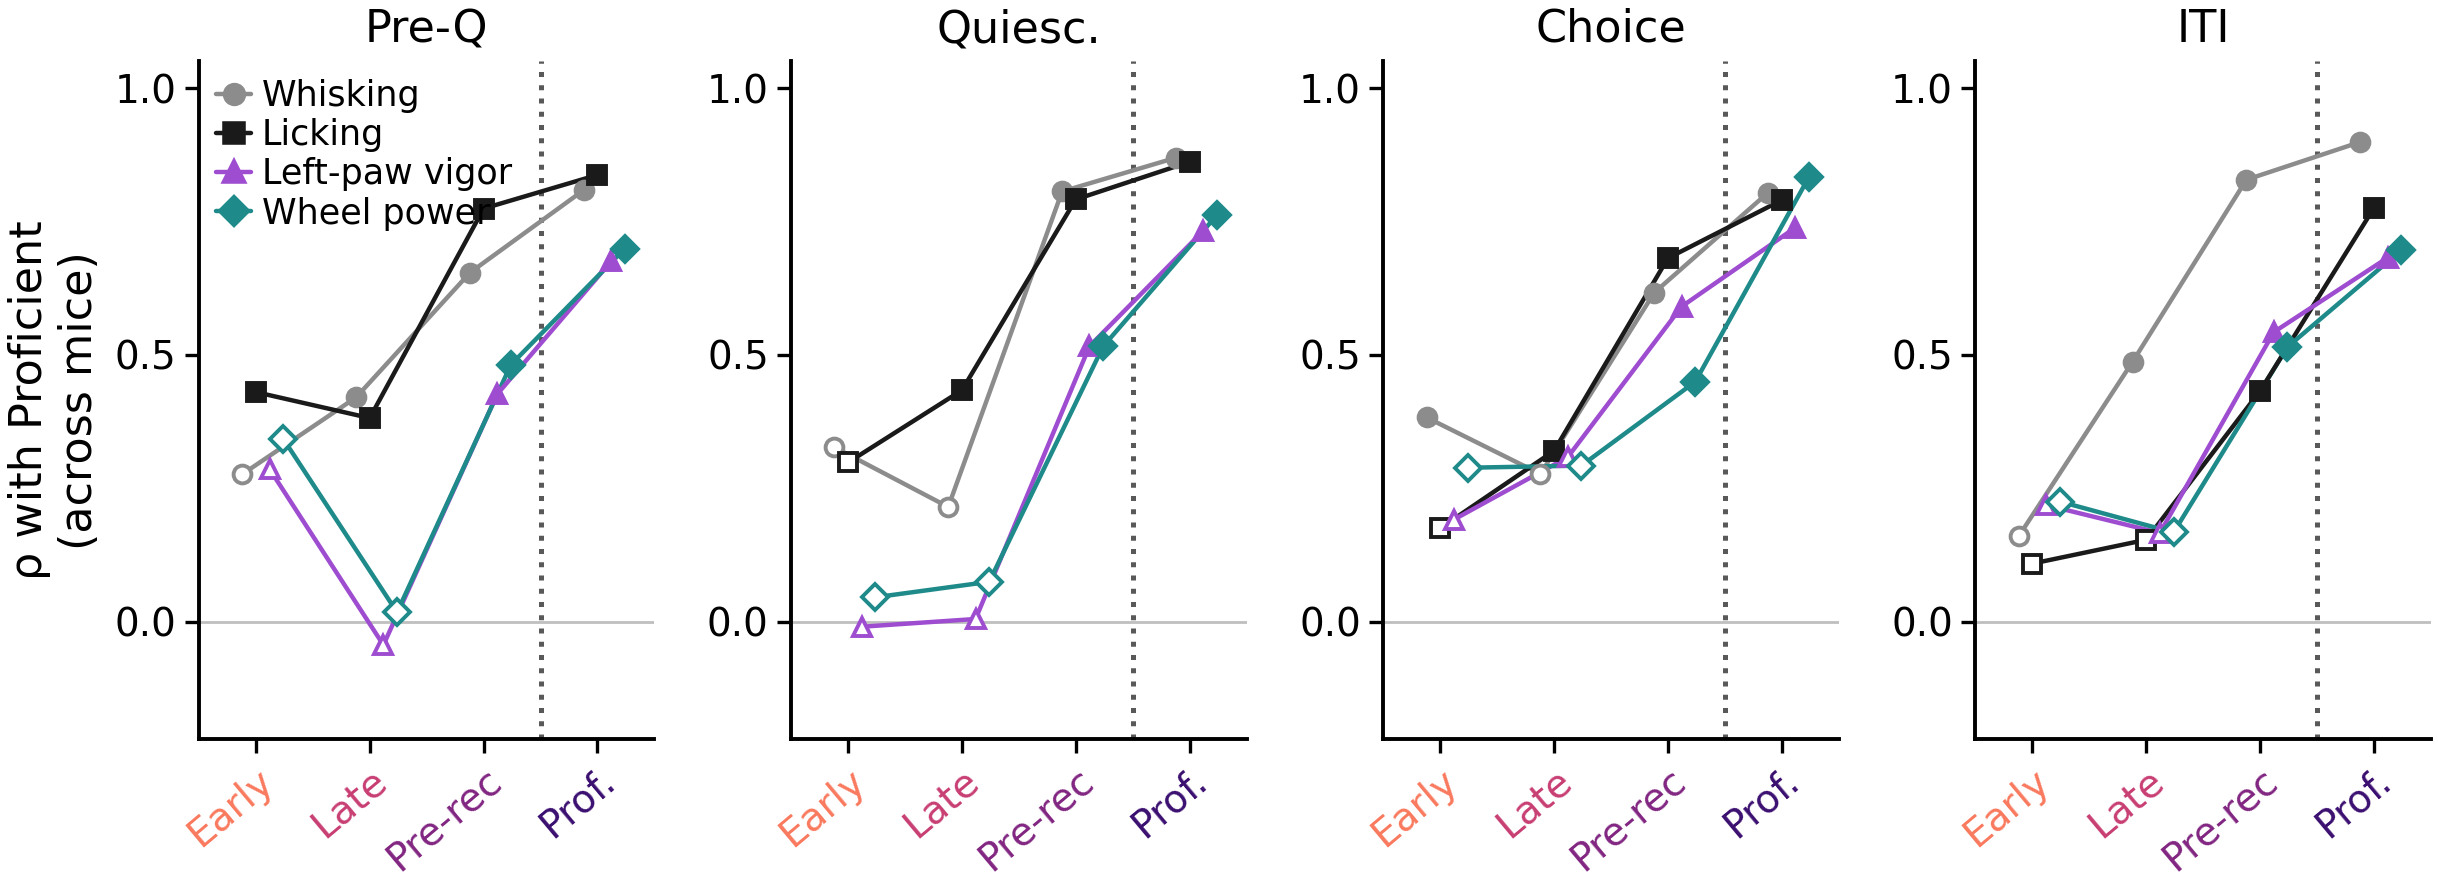

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/time_horizon_epoch_mean


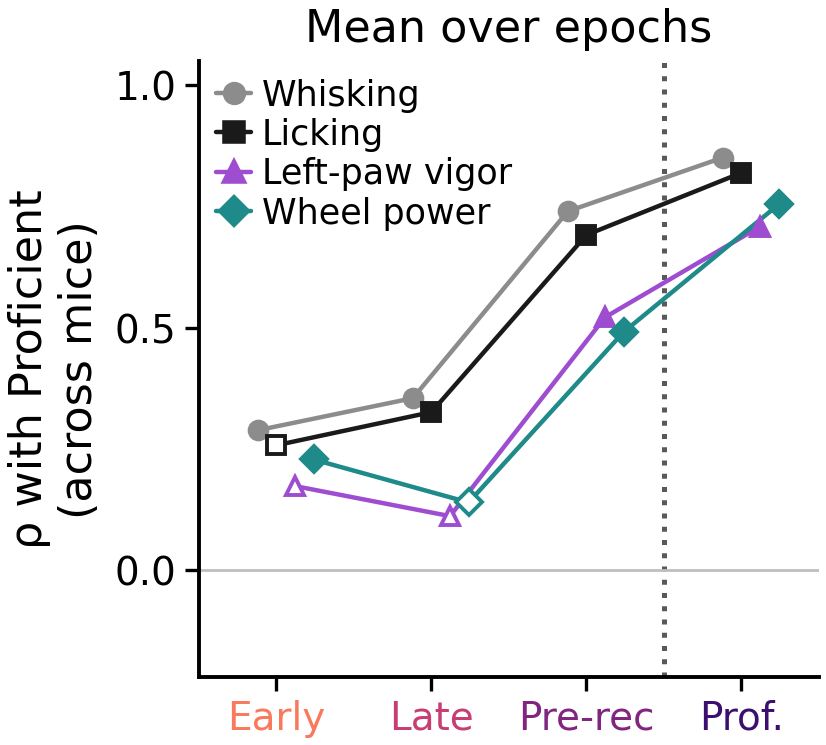

In [9]:
EP_FEATS = TH['PC_FEATS'][:3] + [('wheel_power', 'Wheel power', WHEEL_COLOR, 'D')]
_whole = TH['PROF_CORR']

def draw_epoch(ax_spec, fig, table, title, legend):
    TH['PROF_CORR'], TH['PC_FEATS'] = table, EP_FEATS
    ax, = TH['draw_g'](fig, ax_spec)
    finish_g(ax, table, EP_FEATS)
    ax.set_title(title, fontsize=plt.rcParams['font.size'])
    ax.set_ylim(min(-0.22, table['rho'].min() - 0.08), 1.05)
    if not legend:
        ax.get_legend().remove()
    return ax

fig = plt.figure(figsize=(7.2, 2.2))
g = fig.add_gridspec(1, 4, wspace=0.3)
for i, ep in enumerate(esm.EPOCHS):
    ax = draw_epoch(g[i], fig, EPC[EPC['epoch'] == ep], ep, legend=(i == 0))
    if i:
        ax.set_ylabel('')
    ax.tick_params(axis='x', labelrotation=40)
    for t in ax.get_xticklabels():
        t.set_ha('right'); t.set_rotation_mode('anchor')
save(fig, 'time_horizon_by_epoch'); plt.show()

fig = plt.figure(figsize=(2.0, 2.0))
draw_epoch(fig.add_gridspec(1, 1)[0], fig, EPC[EPC['epoch'] == 'Epoch mean'], 'Mean over epochs', legend=True)
save(fig, 'time_horizon_epoch_mean'); plt.show()
TH['PROF_CORR'] = _whole

## Mice in the LD1–LD2 plane, sessions joined to their mouse (`fig_ld1` A)

The paper's `draw_A` (mouse means ± SEM, sessions as small dots, colour = mouse-mean LD1), plus a thin line from every session to its mouse's mean in the mouse's colour, drawn underneath the dots, so each mouse reads as a star of its sessions.

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
non-emerging metrics: nonemerging_session_metrics_29-09-2026.csv
260 sessions, 56 mice; between-mouse share LD1-3: [0.136 0.099 0.085]


saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/ld1_ld2_mice_spokes


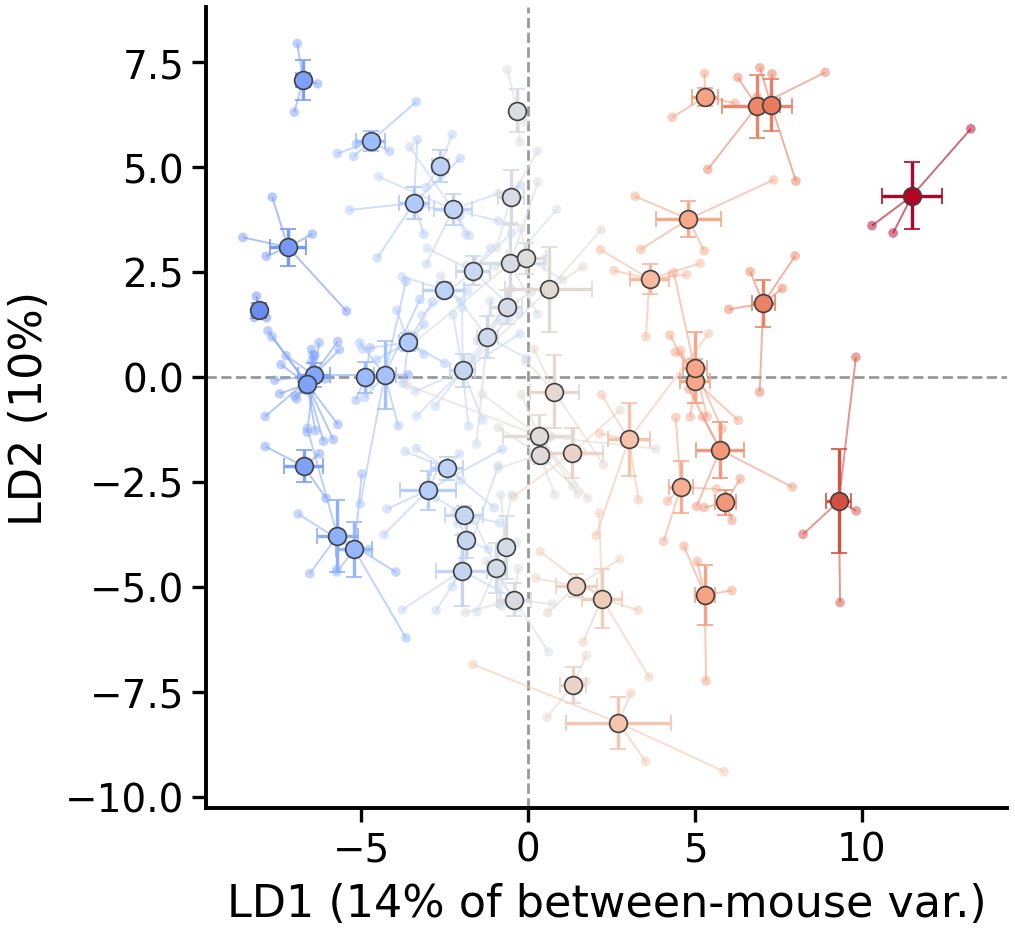

{'colors': ['#EDE8D8',
  '#BFB5C7',
  '#857691',
  '#A96BD3',
  '#B79C50',
  '#7B09AE',
  '#985800',
  '#462600'],
 'vigor_order': [0, 1, 4, 3, 2, 6, 5, 7],
 'lateral': {'left': [3, 5], 'right': [4, 6], 'symmetric': [0, 1, 2, 7]},
 'states_dir': 'data/states_files (identifiable_states // 100)',
 'profiles': 'vigor/paw_bias/state_profiles_19Ago2026.csv',
 'syllable_paw_map': [0, 1, 2, 3, 4, 5, 6, 7]}

In [10]:
from matplotlib.collections import LineCollection
LD1 = run_cells('fig_ld1', ['import lda_shrinkage_core', "FIG = 'fig_ld1'", 'lda = pd.read_pickle(LDA_FILE)', 'def draw_A'])
ld = LD1['lda']
mm = ld.groupby('mouse_name')[['LD1', 'LD2']].mean()
col = dict(zip(mm.index, ps.ld1_colors(mm['LD1'].to_numpy())))   # draw_A's colours

fig = plt.figure(figsize=(2.6, 2.6))
ax, = LD1['draw_A'](fig, fig.add_gridspec(1, 1)[0])
segs = [[(r.LD1, r.LD2), tuple(mm.loc[r.mouse_name])] for r in ld.itertuples()]
ax.add_collection(LineCollection(segs, colors=[col[m] for m in ld['mouse_name']], linewidths=0.35, alpha=0.6,
                                 zorder=0.5))
save(fig, 'ld1_ld2_mice_spokes'); plt.show()
ps.use_paw_states('production')     # fig_ld1 switched to the uniform paw states

## Syllable use along LD1, built up (`fig_ld1` B)

To explain how the panel is read: first both frames (paw states | whisking / licking) with a single trace, Paw 0, and that syllable's own permutation band (grey; the trace is solid where it leaves the band); then the full paper panel. Both carry the paper's legends (in the one-trace slide every entry but Paw 0 is hidden, keeping the layout), same size and y-range, so the two slides overlay exactly.

Each point = for one trial bin, the correlation across the 260 LDA sessions between the session's occupancy of that syllable in that bin and the session's LD1.

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi
non-emerging metrics: nonemerging_session_metrics_29-09-2026.csv
260 sessions, 56 mice; between-mouse share LD1-3: [0.136 0.099 0.085]


260 sessions x 40 bins x 10 syllables


saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/ld1_syllable_corr_full


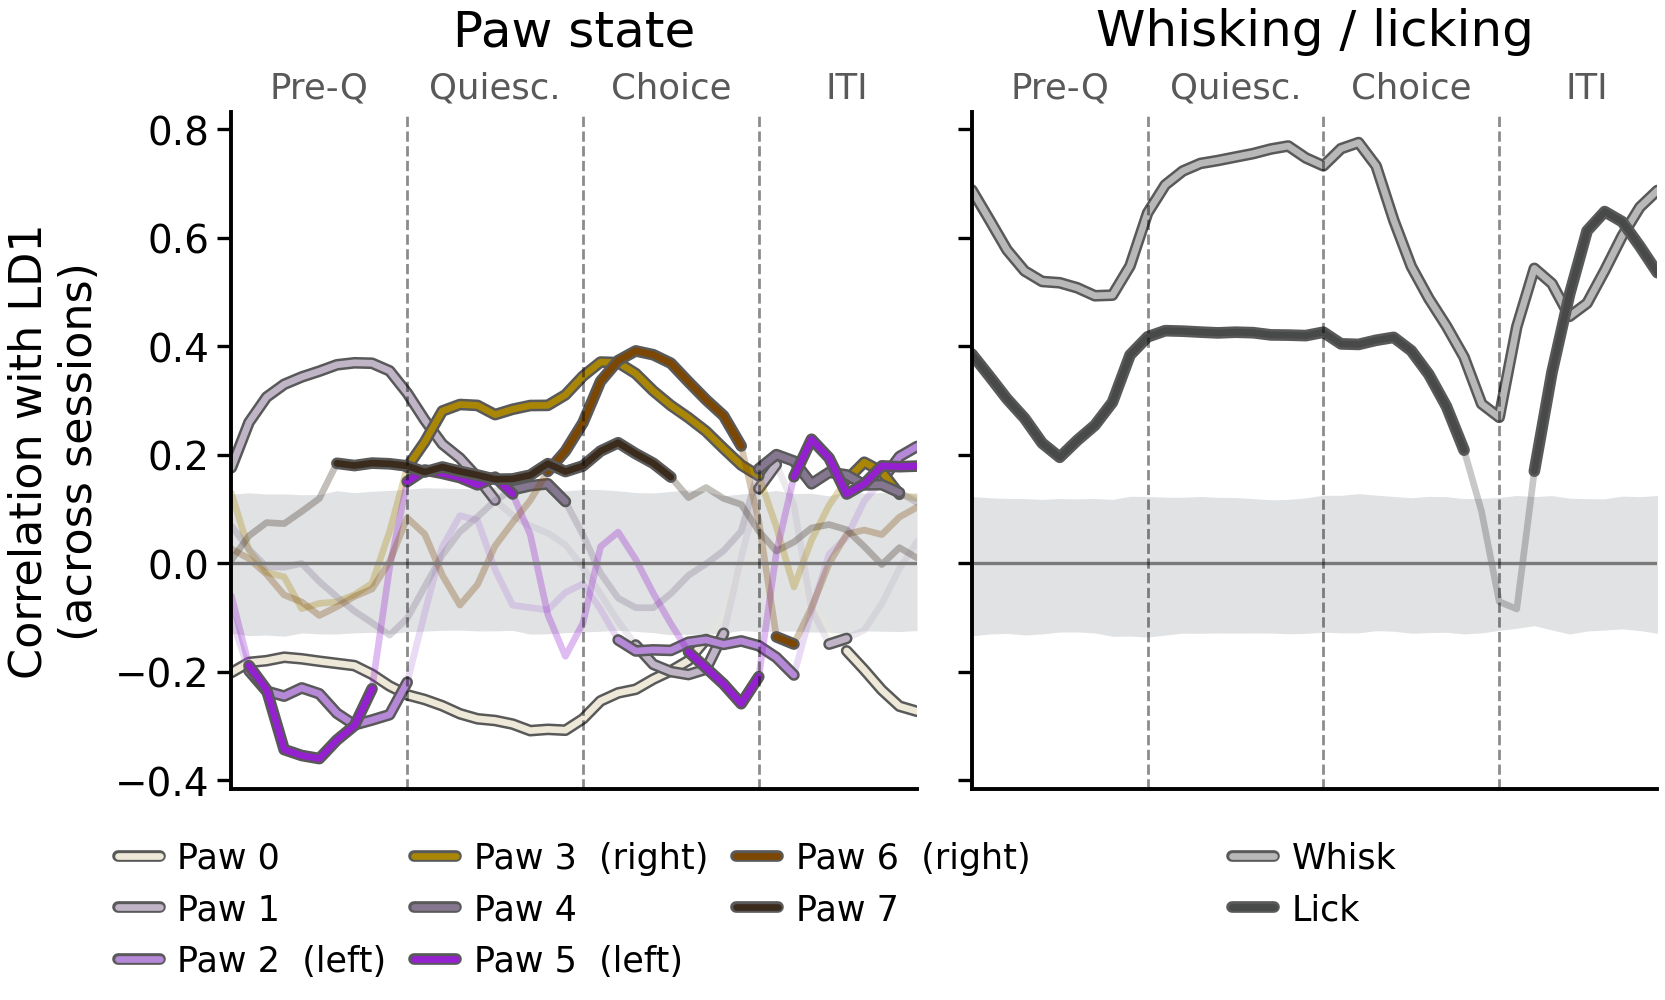

saved /home/ines/repositories/representation_learning_variability/paper-individuality/figure_generation/ciss_figures/ld1_syllable_corr_paw0


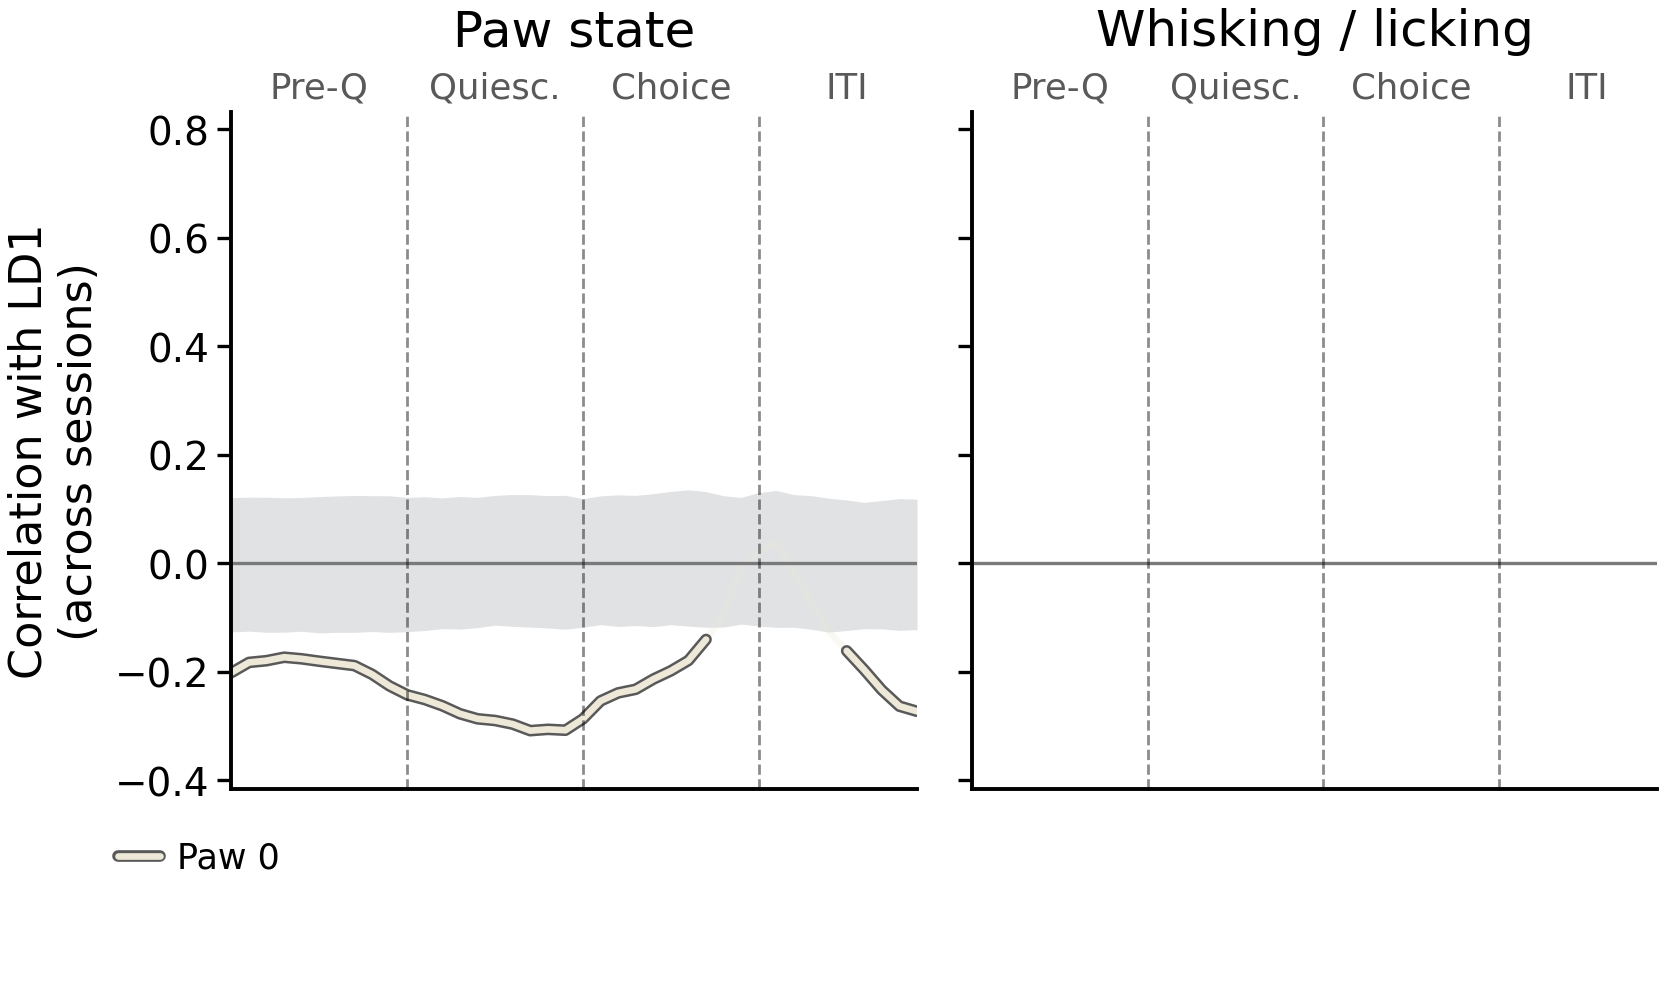

{'colors': ['#EDE8D8',
  '#BFB5C7',
  '#857691',
  '#A96BD3',
  '#B79C50',
  '#7B09AE',
  '#985800',
  '#462600'],
 'vigor_order': [0, 1, 4, 3, 2, 6, 5, 7],
 'lateral': {'left': [3, 5], 'right': [4, 6], 'symmetric': [0, 1, 2, 7]},
 'states_dir': 'data/states_files (identifiable_states // 100)',
 'profiles': 'vigor/paw_bias/state_profiles_19Ago2026.csv',
 'syllable_paw_map': [0, 1, 2, 3, 4, 5, 6, 7]}

In [11]:
from matplotlib.colors import to_hex
LDB = run_cells('fig_ld1', ['import lda_shrinkage_core', "FIG = 'fig_ld1'", 'lda = pd.read_pickle(LDA_FILE)', 'def draw_B'])
SIZE_B = (4.6, 2.2)

# full panel (reference for the y-range, and the last build step)
fig = plt.figure(figsize=SIZE_B)
ax_p, ax_w = LDB['draw_B'](fig, fig.add_gridspec(1, 1)[0], legend=True)
YLIM_B = ax_p.get_ylim()
save(fig, 'ld1_syllable_corr_full'); plt.show()

# one trace: Paw 0
KEEP = 0
fig = plt.figure(figsize=SIZE_B)
ax_p, ax_w = LDB['draw_B'](fig, fig.add_gridspec(1, 1)[0], legend=True)   # the paper's legends, built on all traces
others = {to_hex(c) for i, c in enumerate(LDB['FEAT_COLORS']) if i != KEEP}
for ax in (ax_p, ax_w):
    for ln in list(ax.lines):
        if to_hex(ln.get_color()) in others:
            ln.remove()
    for coll in list(ax.collections):                       # the envelope band over all syllables
        coll.remove()
x = np.arange(LDB['N_BINS'])
ax_p.fill_between(x, LDB['NULL_LO'][:, KEEP], LDB['NULL_HI'][:, KEEP], color=ps.NULL_BAND, alpha=0.3, lw=0)
# the legends keep their full layout (so this slide and the full one line up exactly); every entry but Paw 0 is hidden
for ax in (ax_p, ax_w):
    leg = ax.get_legend()
    for h, t in zip(leg.legend_handles, leg.get_texts()):
        if t.get_text() != LDB['FEAT_LABEL'][KEEP]:
            h.set_visible(False); t.set_visible(False)
ax_p.set_ylim(YLIM_B)
save(fig, 'ld1_syllable_corr_paw0'); plt.show()
ps.use_paw_states('production')     # fig_ld1 switched to the uniform paw states